In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

In [ ]:
# Transformations
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])

# Training dataset
train_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

# Test dataset
test_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

# Data loaders
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 50000
Testing samples: 10000


In [ ]:
class CNN(nn.Module):
    def __init__(self, dropout=False):
        super(CNN, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(64 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 10)

        self.dropout = nn.Dropout(0.5)
        self.use_dropout = dropout

    def forward(self, x):
        x = torch.relu(self.conv1(x))
        x = self.pool(x)

        x = torch.relu(self.conv2(x))
        x = self.pool(x)

        x = x.view(-1, 64 * 8 * 8)

        x = torch.relu(self.fc1(x))

        if self.use_dropout:
            x = self.dropout(x)

        x = self.fc2(x)

        return x

In [ ]:
def train_model(model, optimizer, epochs=5):

    criterion = nn.CrossEntropyLoss()

    train_losses = []
    test_accuracies = []

    for epoch in range(epochs):

        model.train()
        running_loss = 0.0

        for images, labels in train_loader:

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

        avg_loss = running_loss / len(train_loader)

        # Evaluation
        model.eval()

        correct = 0
        total = 0

        with torch.no_grad():

            for images, labels in test_loader:

                outputs = model(images)

                _, predicted = torch.max(outputs.data, 1)

                total += labels.size(0)

                correct += (predicted == labels).sum().item()

        accuracy = 100 * correct / total

        train_losses.append(avg_loss)
        test_accuracies.append(accuracy)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Loss: {avg_loss:.4f} "
            f"Test Accuracy: {accuracy:.2f}%"
        )

    return train_losses, test_accuracies

In [ ]:
model_normal = CNN(dropout=False)

optimizer_normal = optim.Adam(
    model_normal.parameters(),
    lr=0.001
)

loss_normal, acc_normal = train_model(
    model_normal,
    optimizer_normal,
    epochs=5
)

Epoch [1/5] Loss: 1.3344 Test Accuracy: 60.83%
Epoch [2/5] Loss: 0.9579 Test Accuracy: 67.00%
Epoch [3/5] Loss: 0.8038 Test Accuracy: 69.45%
Epoch [4/5] Loss: 0.6907 Test Accuracy: 71.41%
Epoch [5/5] Loss: 0.5939 Test Accuracy: 72.06%


In [ ]:
model_dropout = CNN(dropout=True)

optimizer_dropout = optim.Adam(
    model_dropout.parameters(),
    lr=0.001
)

loss_dropout, acc_dropout = train_model(
    model_dropout,
    optimizer_dropout,
    epochs=5
)

Epoch [1/5] Loss: 1.5181 Test Accuracy: 56.63%
Epoch [2/5] Loss: 1.1948 Test Accuracy: 64.97%
Epoch [3/5] Loss: 1.0577 Test Accuracy: 66.38%
Epoch [4/5] Loss: 0.9691 Test Accuracy: 68.72%
Epoch [5/5] Loss: 0.8986 Test Accuracy: 70.16%


In [ ]:
model_l2 = CNN(dropout=False)

optimizer_l2 = optim.Adam(
    model_l2.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

loss_l2, acc_l2 = train_model(
    model_l2,
    optimizer_l2,
    epochs=5
)

Epoch [1/5] Loss: 1.3312 Test Accuracy: 60.57%
Epoch [2/5] Loss: 0.9597 Test Accuracy: 68.72%
Epoch [3/5] Loss: 0.8112 Test Accuracy: 70.18%
Epoch [4/5] Loss: 0.6995 Test Accuracy: 72.46%
Epoch [5/5] Loss: 0.6017 Test Accuracy: 71.84%


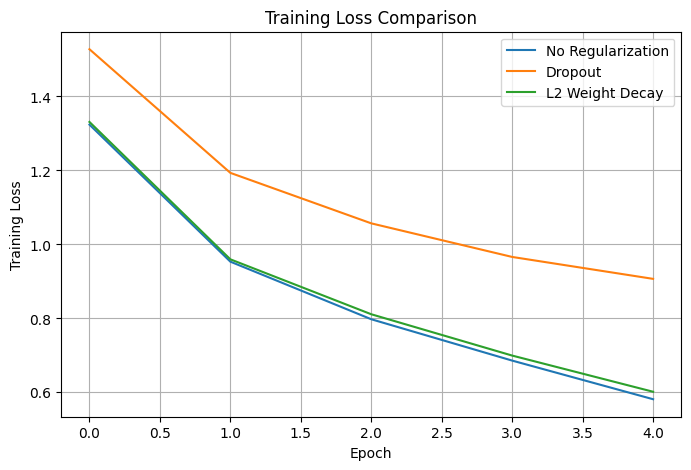

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(loss_normal, label="No Regularization")
plt.plot(loss_dropout, label="Dropout")
plt.plot(loss_l2, label="L2 Weight Decay")

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Comparison")
plt.legend()
plt.grid()

plt.show()

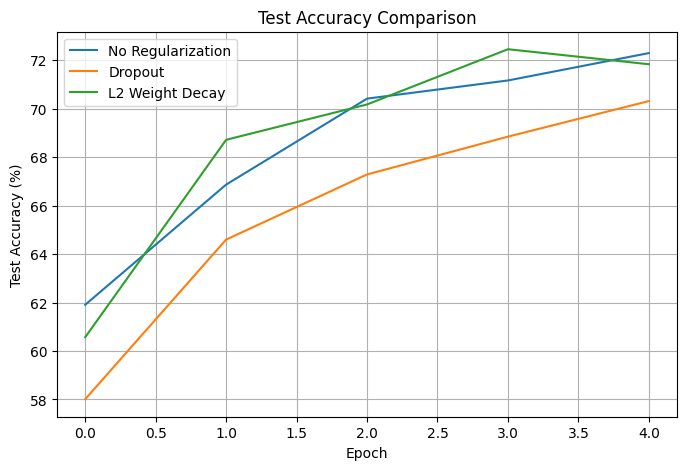

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(acc_normal, label="No Regularization")
plt.plot(acc_dropout, label="Dropout")
plt.plot(acc_l2, label="L2 Weight Decay")

plt.xlabel("Epoch")
plt.ylabel("Test Accuracy (%)")
plt.title("Test Accuracy Comparison")
plt.legend()
plt.grid()

plt.show()

In [ ]:
print("\nFinal Test Accuracy")
print("--------------------------")

print("Without Regularization:",
      f"{acc_normal[-1]:.2f}%")

print("With Dropout:",
      f"{acc_dropout[-1]:.2f}%")

print("With L2 Weight Decay:",
      f"{acc_l2[-1]:.2f}%")


Final Test Accuracy
--------------------------
Without Regularization: 72.30%
With Dropout: 70.32%
With L2 Weight Decay: 71.84%
